# Machine Learning 실습

M애플리케이션배포 · 2026-11-13

수업의 Iris 분류 실습과 첨부 자료의 모델 평가·거리 계산을 Python으로 실행한다.
추가로 참고 엑셀의 공분산, KNN, Gini, Log loss, 경사하강법을 재현한다.

**실행:** Python 3.12 이상에서 `pip install -r requirements.txt`를 실행한 다음 이 노트북의
커널을 다시 시작하고 모든 셀을 순서대로 실행한다. Iris는 scikit-learn 내장 데이터여서
별도 데이터 다운로드가 필요 없다. 엑셀 예제는 제공 파일의 저장된 계산값을 아래 셀에 담았다.
RAND 함수가 포함된 원본을 다시 계산하면 다른 숫자가 나오므로 저장된 값과 난수 예제를 구분한다.

**평가 방법:** 학습/테스트를 먼저 분리한다. 모델 및 매개변수 선택에는 학습 데이터의 5-fold
교차검증만 사용한다. 최종 선택 후 테스트 데이터를 한 번 평가한다.

In [1]:
import sys
import time
import platform
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay, roc_curve,
    roc_auc_score, precision_recall_curve, average_precision_score, log_loss,
    mean_squared_error)
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
import optuna

SEED = 42
rng = np.random.default_rng(SEED)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 12)
print('Python:', platform.python_version())
display(pd.Series({p: version(p) for p in ['numpy','pandas','scikit-learn','matplotlib',
    'seaborn','xgboost','lightgbm','optuna']}, name='version').to_frame())

Python: 3.12.14


,version
numpy,2.3.5
pandas,3.0.1
scikit-learn,1.9.1
matplotlib,3.11.2
seaborn,0.13.2
xgboost,3.4.1
lightgbm,4.7.0
optuna,5.0.0


## 1. Iris 데이터 확인 및 EDA

특성은 꽃받침 길이·너비, 꽃잎 길이·너비의 4개이고 목표는 붓꽃 품종 3개이다.
전체 150개는 품종마다 50개씩이다. 먼저 분할한 뒤 학습 데이터에서 결측치·분포·상관관계를 살핀다.
분류 정답인 target을 입력 특성으로 사용하지 않는다.

In [2]:
iris = load_iris(as_frame=True)
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)
train_df = X_train.copy()
train_df['species'] = y_train.map(dict(enumerate(iris.target_names)))
print('전체/훈련/테스트:', X.shape, X_train.shape, X_test.shape)
print('학습 데이터 결측치:', int(X_train.isna().sum().sum()))
display(train_df.head())
display(X_train.describe().round(3))
display(train_df['species'].value_counts().to_frame('count'))
assert X.shape == (150, 4) and len(X_train) == 120 and len(X_test) == 30
assert set(X_train.index).isdisjoint(X_test.index)

전체/훈련/테스트: (150, 4) (120, 4) (30, 4)
학습 데이터 결측치: 0


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
8,4.4,2.9,1.4,0.2,setosa
106,4.9,2.5,4.5,1.7,virginica
76,6.8,2.8,4.8,1.4,versicolor
9,4.9,3.1,1.5,0.1,setosa
89,5.5,2.5,4.0,1.3,versicolor


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,120.000,120.000,120.000,120.000
mean,5.842,3.048,3.770,1.205
std,0.841,0.449,1.769,0.763
min,4.300,2.000,1.100,0.100
25%,5.100,2.800,1.600,0.300
50%,5.750,3.000,4.250,1.300
75%,6.400,3.325,5.100,1.800
max,7.900,4.400,6.900,2.500


,count
species,
setosa,40
virginica,40
versicolor,40


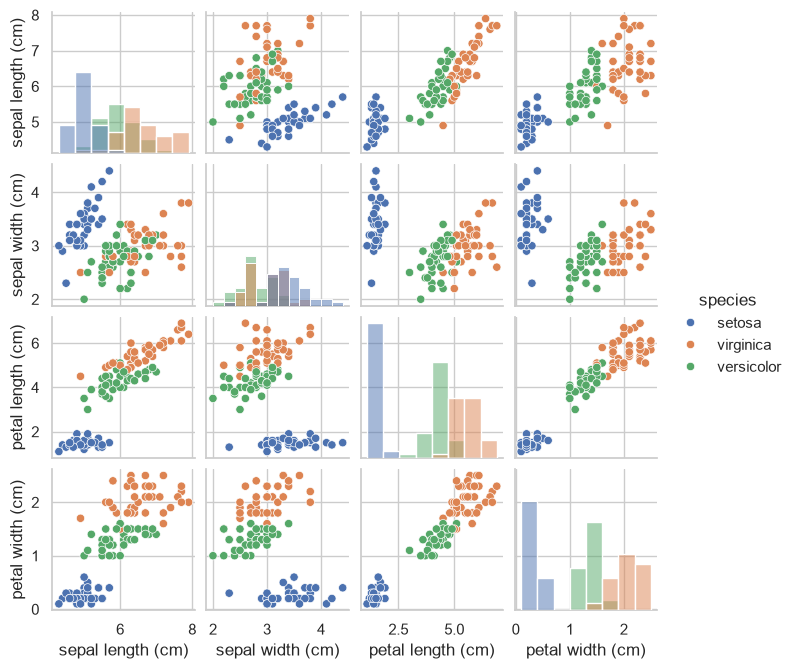

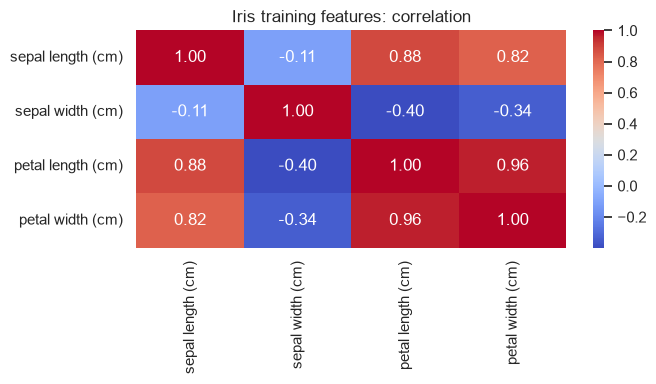

In [3]:
sns.pairplot(train_df, hue='species', diag_kind='hist', height=1.7)
plt.show()
fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(X_train.corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=ax)
ax.set_title('Iris training features: correlation')
plt.tight_layout()
plt.show()

꽃잎 길이와 너비의 관계, 품종별 군집을 비교한다. 상관계수는 두 수치 변수의 선형 관계를 나타내며
인과관계를 뜻하지 않는다. KNN이나 규제 회귀처럼 크기에 민감한 모델은 전처리를 Pipeline 안에 둔다.

## 2. 기준 모델, 결정 트리 및 교차검증

최빈 품종만 예측하는 DummyClassifier를 기준으로 삼는다. 균등한 세 품종에서는 약 1/3이다.
결정 트리는 질문을 반복해 공간을 나눈다. 깊이가 커질수록 학습 데이터를 외울 수 있으므로
학습 점수와 교차검증 점수를 함께 비교한다.

,max_depth,train_accuracy,cv_accuracy,cv_std
0,1,0.6667,0.6667,0.0000
1,2,0.9667,0.9417,0.0204
2,3,0.9792,0.9583,0.0264
3,5,0.9979,0.9500,0.0167
4,None,1.0000,0.9500,0.0167


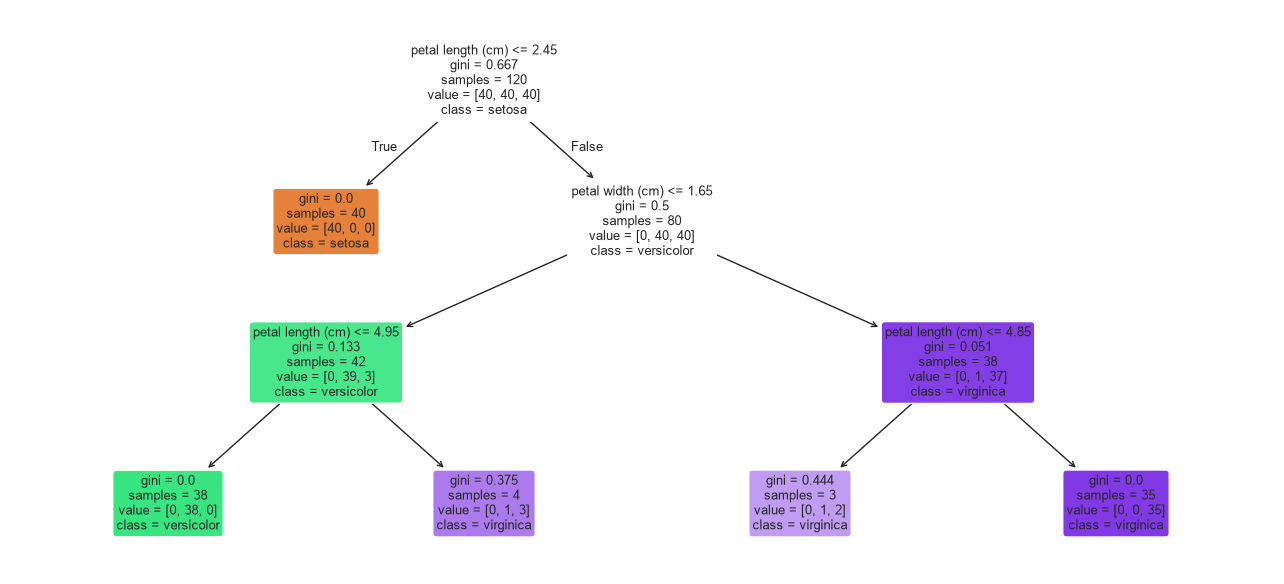

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
dummy = DummyClassifier(strategy='most_frequent')
dt = DecisionTreeClassifier(max_depth=3, random_state=SEED)
depth_results = []
for depth in [1, 2, 3, 5, None]:
    candidate = DecisionTreeClassifier(max_depth=depth, random_state=SEED)
    scores = cross_validate(candidate, X_train, y_train, cv=cv,
        scoring='accuracy', return_train_score=True)
    depth_results.append({'max_depth': str(depth),
        'train_accuracy': scores['train_score'].mean(),
        'cv_accuracy': scores['test_score'].mean(),
        'cv_std': scores['test_score'].std()})
display(pd.DataFrame(depth_results).round(4))
dt.fit(X_train, y_train)
fig, ax = plt.subplots(figsize=(13, 6))
plot_tree(dt, feature_names=list(X.columns), class_names=list(iris.target_names),
    filled=True, rounded=True, ax=ax, fontsize=9)
plt.tight_layout()
plt.show()

## 3. GridSearchCV와 앙상블 비교

GridSearchCV는 정한 후보 조합을 모두 교차검증한다. Random Forest는 여러 트리의 투표로
분산을 줄이는 배깅 방식이다. XGBoost와 LightGBM은 앞선 모델의 부족한 부분을 보완하는
부스팅 방식이다. 아래 표의 점수는 테스트 점수가 아니라 **학습 자료 내부의 CV 점수**다.

In [5]:
grid = GridSearchCV(DecisionTreeClassifier(random_state=SEED),
    {'max_depth': [1,2,3,4,5], 'min_samples_split': [2,3,4]},
    cv=cv, scoring='accuracy', n_jobs=1)
grid.fit(X_train, y_train)
print('Decision Tree best parameters:', grid.best_params_)
print('Best training CV accuracy:', round(grid.best_score_, 4))
models = {
    'Dummy': dummy,
    'Decision Tree': dt,
    'Tuned Decision Tree': grid.best_estimator_,
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=1),
    'XGBoost': XGBClassifier(n_estimators=100, learning_rate=0.1, random_state=SEED,
        eval_metric='mlogloss', n_jobs=1),
    'LightGBM': LGBMClassifier(n_estimators=100, learning_rate=0.1, random_state=SEED,
        verbosity=-1, n_jobs=1),
    'KNN': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
}
cv_results = []
for name, model in models.items():
    start = time.perf_counter()
    result = cross_validate(model, X_train, y_train, cv=cv,
        scoring={'accuracy': 'accuracy', 'f1_macro': 'f1_macro'})
    cv_results.append({'model': name, 'cv_accuracy': result['test_accuracy'].mean(),
        'cv_std': result['test_accuracy'].std(),
        'cv_macro_f1': result['test_f1_macro'].mean(),
        'cv_time_seconds': time.perf_counter()-start})
cv_table = pd.DataFrame(cv_results)
display(cv_table.sort_values('cv_accuracy', ascending=False).round(4))

Decision Tree best parameters: {'max_depth': 3, 'min_samples_split': 2}
Best training CV accuracy: 0.9583


,model,cv_accuracy,cv_std,cv_macro_f1,cv_time_seconds
1,Decision Tree,0.9583,0.0264,0.9580,0.0408
2,Tuned Decision Tree,0.9583,0.0264,0.9580,0.0416
6,KNN,0.9583,0.0264,0.9580,0.0933
5,LightGBM,0.9583,0.0264,0.9580,0.2255
4,XGBoost,0.9500,0.0312,0.9496,1.0475
3,Random Forest,0.9500,0.0312,0.9494,0.9478
0,Dummy,0.3333,0.0000,0.1667,0.0286


## 4. Optuna로 Random Forest 조정

TPE가 다음 탐색 후보를 선택한다. 수업 자료와 동일하게 50회 탐색하며 난수 시드는 42다.
목적함수는 학습 데이터의 교차검증 정확도이다. 테스트 자료로 여러 번 최적화하면
테스트 정답에 맞춘 선택이 되므로 목적함수에서 테스트 자료에 접근하지 않는다.
후보 선택에 사용한 CV의 최고 점수는 다소 낙관적일 수 있으며 최종 평가는 별도 테스트로 한다.

In [6]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 10, 200),
        'max_depth': trial.suggest_int('max_depth', 2, 20),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 10),
    }
    model = RandomForestClassifier(**params, random_state=SEED, n_jobs=1)
    return float(cross_validate(model, X_train, y_train, cv=cv,
        scoring='accuracy')['test_score'].mean())

study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
start = time.perf_counter()
study.optimize(objective, n_trials=50)
print('완료 trial:', len(study.trials))
print('최적 매개변수:', study.best_params)
print('최고 training CV accuracy:', round(study.best_value, 4))
models['Optuna Random Forest'] = RandomForestClassifier(**study.best_params,
    random_state=SEED, n_jobs=1)
opt_result = cross_validate(models['Optuna Random Forest'], X_train, y_train,
    cv=cv, scoring={'accuracy': 'accuracy', 'f1_macro': 'f1_macro'})
cv_table = pd.concat([cv_table, pd.DataFrame([{
    'model': 'Optuna Random Forest', 'cv_accuracy': opt_result['test_accuracy'].mean(),
    'cv_std': opt_result['test_accuracy'].std(),
    'cv_macro_f1': opt_result['test_f1_macro'].mean(),
    'cv_time_seconds': time.perf_counter()-start}])], ignore_index=True)
display(cv_table.sort_values('cv_accuracy', ascending=False).round(4))
print('Optuna 시간은 탐색 전체를 포함하고 다른 행의 시간은 5-fold 평가 시간이다.')

완료 trial: 50
최적 매개변수: {'n_estimators': 45, 'max_depth': 7, 'min_samples_split': 6}
최고 training CV accuracy: 0.9667


,model,cv_accuracy,cv_std,cv_macro_f1,cv_time_seconds
7,Optuna Random Forest,0.9667,0.0312,0.9663,36.4206
1,Decision Tree,0.9583,0.0264,0.9580,0.0408
5,LightGBM,0.9583,0.0264,0.9580,0.2255
2,Tuned Decision Tree,0.9583,0.0264,0.9580,0.0416
6,KNN,0.9583,0.0264,0.9580,0.0933
3,Random Forest,0.9500,0.0312,0.9494,0.9478
4,XGBoost,0.9500,0.0312,0.9496,1.0475
0,Dummy,0.3333,0.0000,0.1667,0.0286


Optuna 시간은 탐색 전체를 포함하고 다른 행의 시간은 5-fold 평가 시간이다.


## 5. 최종 테스트와 혼동행렬

선택 기준은 CV 정확도, 동점이면 CV macro F1, 그다음 모델 이름 순이다.
순서를 먼저 정하고 최종 모델을 선택한 뒤 보관한 테스트 30개를 평가한다.
행은 실제 품종, 열은 예측 품종이다. macro 평균은 품종을 똑같이 취급하고,
weighted 평균은 각 품종의 실제 표본 수를 가중치로 사용한다.

CV로 선택한 최종 모델: Optuna Random Forest
Baseline test accuracy: 0.3333
Final test accuracy: 0.9667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



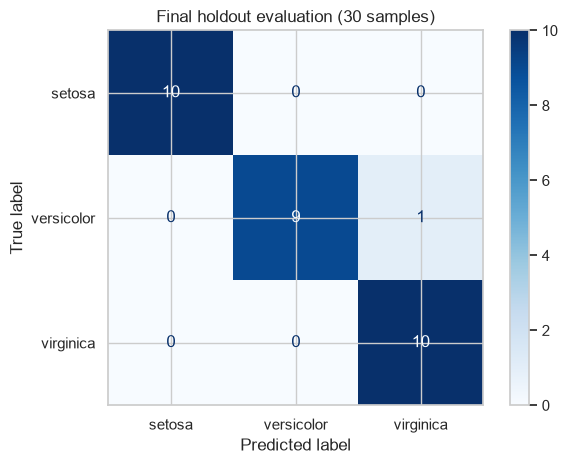

테스트 표본이 30개라 오답 하나당 정확도가 약 3.33%p 달라진다.


In [7]:
ranking = cv_table.sort_values(['cv_accuracy','cv_macro_f1','model'],
    ascending=[False,False,True], kind='stable')
selected_name = ranking.iloc[0]['model']
final_model = clone(models[selected_name]).fit(X_train, y_train)
test_pred = final_model.predict(X_test)
baseline = clone(dummy).fit(X_train, y_train)
baseline_accuracy = accuracy_score(y_test, baseline.predict(X_test))
final_accuracy = accuracy_score(y_test, test_pred)
print('CV로 선택한 최종 모델:', selected_name)
print(f'Baseline test accuracy: {baseline_accuracy:.4f}')
print(f'Final test accuracy: {final_accuracy:.4f}')
print(classification_report(y_test, test_pred, target_names=iris.target_names, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred,
    display_labels=iris.target_names, cmap='Blues')
plt.title('Final holdout evaluation (30 samples)')
plt.tight_layout()
plt.show()
assert confusion_matrix(y_test, test_pred).sum() == len(y_test)
assert np.isclose(baseline_accuracy, 1/3)
print('테스트 표본이 30개라 오답 하나당 정확도가 약 3.33%p 달라진다.')

## 6. 참고 PDF의 평가 지표 직접 계산

PDF 4쪽의 예제는 TN=88, FP=2, FN=3, TP=7이다.

| 지표 | 식 | 의미 |
|---|---|---|
| Accuracy | (TP+TN)/전체 | 전체 중 맞힌 비율 |
| Precision | TP/(TP+FP) | 양성이라고 예측한 것 중 실제 양성 |
| Recall (TPR) | TP/(TP+FN) | 실제 양성 중 찾아낸 비율 |
| FPR | FP/(FP+TN) | 실제 음성을 양성으로 오판한 비율 |
| F1 | 2×Precision×Recall/(Precision+Recall) | 정밀도와 재현율의 조화평균 |

PDF 5쪽 FPR의 `FN/N` 표기는 `FP/N`으로, 8쪽 `2/2=0.5` 표기는
`2/4=0.5`로 계산한다. N은 실제 음성 수, P는 실제 양성 수다.

In [8]:
tn, fp, fn, tp = 88, 2, 3, 7
manual_metrics = pd.Series({
    'accuracy': (tp+tn)/(tp+tn+fp+fn), 'precision': tp/(tp+fp),
    'recall': tp/(tp+fn), 'FPR': fp/(fp+tn),
    'F1': 2*tp/(2*tp+fp+fn)})
display(manual_metrics.to_frame('value').round(6))
reference_true = np.array([0]*90 + [1]*10)
reference_pred = np.array([0]*88 + [1]*2 + [0]*3 + [1]*7)
assert confusion_matrix(reference_true, reference_pred).tolist() == [[88,2],[3,7]]
assert np.isclose(manual_metrics['F1'], f1_score(reference_true, reference_pred))
assert np.isclose(manual_metrics['accuracy'], .95)

,value
accuracy,0.950000
precision,0.777778
recall,0.700000
FPR,0.022222
F1,0.736842


## 7. 엑셀 예제: 임계값, ROC, PR 및 불균형 데이터

출처: 첨부 엑셀 `confusion matrix!C3:D42`의 저장된 예제 값(40개).
실제 사람에 대한 진단 데이터가 아닌 수업의 난수 생성 예제다.
원본 IF 식과 같이 **score > threshold**일 때 양성으로 처리한다.
따라서 정확히 0.5인 값은 threshold=0.5에서 음성이다.
ROC 곡선 라이브러리는 score≥threshold인 지점을 반환하므로 경계의 의미를 구분한다.

임계값을 낮추면 양성 예측이 늘어 보통 재현율과 오탐률이 함께 높아진다.
ROC AUC는 순위 구별 능력을, PR 곡선과 AP는 양성 검출의 정밀도·재현율 관계를 나타낸다.
AP는 PR 곡선의 단순 사다리꼴 면적과 같은 값으로 취급하지 않는다.

In [9]:
y_binary = np.array([1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])
scores_binary = np.array([0.99, 0.5, 0.48, 0.82, 0.48, 0.25, 0.31, 0.41, 0.51, 0.45, 0.57, 0.65, 0.64, 0.56, 0.24, 0.56, 0.64, 0.29, 0.47, 0.23, 0.35, 0.66, 0.65, 0.61, 0.64, 0.32, 0.28, 0.6, 0.25, 0.29, 0.68, 0.49, 0.64, 0.63, 0.46, 0.47, 0.45, 0.64, 0.27, 0.59])

,threshold,TN,FP,FN,TP,accuracy,precision,recall_TPR,FPR,F1
0,0.2,0,35,0,5,0.125,0.1250,1.0,1.0000,0.2222
1,0.5,18,17,3,2,0.500,0.1053,0.4,0.4857,0.1667
2,0.8,35,0,3,2,0.925,1.0000,0.4,0.0000,0.5714


실제 양성 수: 5 / 40
모두 음성이라고 할 때 accuracy: 0.875
ROC AUC: 0.6971428571428572
Average precision: 0.5169565217391305
모든 예측이 음성이면 precision은 0으로 표시했다(zero_division=0).


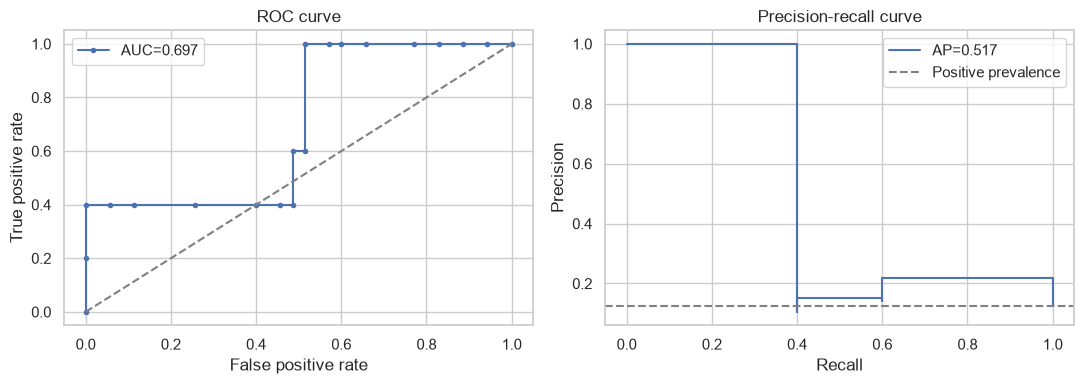

In [10]:
threshold_rows = []
for threshold in [0.2, 0.5, 0.8]:
    pred = (scores_binary > threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_binary, pred, labels=[0,1]).ravel()
    threshold_rows.append({'threshold': threshold, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
        'accuracy': accuracy_score(y_binary,pred),
        'precision': precision_score(y_binary,pred,zero_division=0),
        'recall_TPR': recall_score(y_binary,pred,zero_division=0),
        'FPR': fp/(fp+tn), 'F1': f1_score(y_binary,pred,zero_division=0)})
display(pd.DataFrame(threshold_rows).round(4))
print('실제 양성 수:', int(y_binary.sum()), '/', len(y_binary))
print('모두 음성이라고 할 때 accuracy:', (y_binary==0).mean())
print('ROC AUC:', roc_auc_score(y_binary, scores_binary))
print('Average precision:', average_precision_score(y_binary, scores_binary))
print('모든 예측이 음성이면 precision은 0으로 표시했다(zero_division=0).')

fpr, tpr, roc_thresholds = roc_curve(y_binary, scores_binary)
precision, recall, pr_thresholds = precision_recall_curve(y_binary, scores_binary)
fig, axes = plt.subplots(1,2,figsize=(11,4))
axes[0].plot(fpr,tpr,marker='.', label=f'AUC={roc_auc_score(y_binary,scores_binary):.3f}')
axes[0].plot([0,1],[0,1],'--',color='gray')
axes[0].set(xlabel='False positive rate',ylabel='True positive rate',title='ROC curve')
axes[1].step(recall,precision,where='post',label=f'AP={average_precision_score(y_binary,scores_binary):.3f}')
axes[1].axhline(y_binary.mean(),linestyle='--',color='gray',label='Positive prevalence')
axes[1].set(xlabel='Recall',ylabel='Precision',title='Precision-recall curve')
for ax in axes: ax.legend()
plt.tight_layout()
plt.show()

양성이 5개뿐인 이 예제에서 모두 음성으로 분류하면 정확도는 87.5%지만 재현율은 0이다.
따라서 정확도 하나만으로 모델이 좋다고 판단할 수 없다. 원본 난수 생성 예제의 결과를
실제 서비스의 성능으로 해석하지 않는다.

## 8. PDF 거리 계산과 엑셀 KNN 재현

Euclidean(L2) 거리는 차이 제곱합의 제곱근, Manhattan(L1) 거리는 차이 절댓값의 합이다.
단위가 다른 특성은 거리를 지배할 수 있으므로 KNN에서 표준화가 유용하다.
PDF 15~16쪽의 좌표를 직접 계산하고, 엑셀 KNN의 저장된 10개 점과 새 점을 사용한다.

In [11]:
distance_rows = []
for a,b in [([150,250],[155,255]), ([150,250,300],[155,255,250])]:
    delta = np.asarray(a)-np.asarray(b)
    distance_rows.append({'A': str(a),'B': str(b),
        'Euclidean': np.sqrt(np.sum(delta**2)), 'Manhattan': np.abs(delta).sum()})
display(pd.DataFrame(distance_rows))
assert np.isclose(distance_rows[0]['Euclidean'], np.sqrt(50))
assert np.isclose(distance_rows[1]['Euclidean'], np.sqrt(2550))
assert [r['Manhattan'] for r in distance_rows] == [10,60]

,A,B,Euclidean,Manhattan
0,"[150, 250]","[155, 255]",7.071068,10
1,"[150, 250, 300]","[155, 255, 250]",50.497525,60


In [12]:
# 출처: KNN_classification!A4:C13 및 C18:D18
points = np.array([[0.989906463137069, 0.9013559781262908], [0.12852906698014288, 0.10299889211263746], [0.6922637637480094, 0.2669462897992235], [0.7511669564943233, 0.3005045901721821], [0.5708233334629012, 0.9001668168091544], [0.48472026545477376, 0.6752086798371295], [0.8260099481811954, 0.6125909941814319], [0.8108351700643792, 0.1836920245617908], [0.0626462312037469, 0.8903779503483069], [0.42974948975347693, 0.8347633427275156]])
labels = np.array([1, 0, 0, 1, 1, 1, 1, 0, 0, 1])
query = np.array([0.7998875372260548, 0.24095392683393824])

In [13]:
distances = np.linalg.norm(points-query, axis=1)
neighbor_idx = np.argsort(distances, kind='stable')[:5]
votes = np.bincount(labels[neighbor_idx], minlength=2)
manual_prediction = int(np.argmax(votes))
knn_model = KNeighborsClassifier(n_neighbors=5).fit(points, labels)
sklearn_prediction = int(knn_model.predict(query.reshape(1,-1))[0])
display(pd.DataFrame({'neighbor_index': neighbor_idx+1,
    'distance': distances[neighbor_idx], 'label': labels[neighbor_idx]}))
print('다수결 예측 / sklearn 예측:', manual_prediction, sklearn_prediction)
assert manual_prediction == sklearn_prediction

,neighbor_index,distance,label
0,8,0.058299,0
1,4,0.076941,1
2,3,0.110718,0
3,7,0.372554,1
4,6,0.536570,1


다수결 예측 / sklearn 예측: 1 1


## 9. Gini 불순도와 Log loss

Gini=1−Σp²이며 이진 분류에서는 2p(1−p)다. 두 클래스가 반반이면 0.5,
한 클래스만 있으면 0이다. 엑셀의 양성/음성 개수로 비율을 다시 계산한다.

이진 Log loss는 −[y ln(p)+(1−y) ln(1−p)]의 평균이다.
틀린 예측을 높은 확신으로 하면 손실이 커진다. 0과 1에서 로그가 발산하므로 작은 ε로 자른다.

In [14]:
# 출처: gini!B3:L4, log loss plot!B5:C24의 저장된 값
positive_counts = np.arange(10,-1,-1)
negative_counts = 10-positive_counts
prob = positive_counts/(positive_counts+negative_counts)
gini_table = pd.DataFrame({'positive':positive_counts,'negative':negative_counts,
    'p':prob,'gini':2*prob*(1-prob)})
display(gini_table)
loss_y = np.array([1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1])
loss_p = np.array([0.5840846058116118, 0.2791653399156737, 0.6880424410459642, 0.24369037790656656, 0.35711238292797975, 0.9058102055773414, 0.2866552025295911, 0.47615784915049, 0.11728254561632212, 0.0017616688681162396, 0.35994441535921406, 0.42793953052644185, 0.40496895240911357, 0.2906886829055536, 0.8903269579882458, 0.616085507597813, 0.7873938973167608, 0.12371256488251581, 0.8653844765993586, 0.5918880021609003])
p_safe = np.clip(loss_p,1e-15,1-1e-15)
per_item_loss = -(loss_y*np.log(p_safe)+(1-loss_y)*np.log(1-p_safe))
display(pd.DataFrame({'actual':loss_y,'probability':loss_p,'loss':per_item_loss}).head())
print('평균 수식 계산:', per_item_loss.mean())
print('sklearn log_loss:', log_loss(loss_y,loss_p,labels=[0,1]))
assert np.isclose(per_item_loss.mean(),log_loss(loss_y,loss_p,labels=[0,1]))
assert np.isclose(gini_table['gini'].max(),.5)

,positive,negative,p,gini
0,10,0,1.0,0.00
1,9,1,0.9,0.18
2,8,2,0.8,0.32
3,7,3,0.7,0.42
4,6,4,0.6,0.48
5,5,5,0.5,0.50
6,4,6,0.4,0.48
7,3,7,0.3,0.42
8,2,8,0.2,0.32
9,1,9,0.1,0.18


,actual,probability,loss
0,1,0.584085,0.537709
1,1,0.279165,1.275951
2,0,0.688042,1.164888
3,1,0.243690,1.411857
4,0,0.357112,0.441785


평균 수식 계산: 0.7904462950272916
sklearn log_loss: 0.7904462950272916


## 10. 공분산과 상관계수

공분산은 함께 증가·감소하는 방향을 나타내며 원래 단위의 영향을 받는다.
상관계수는 −1~1로 표준화한 선형 관계다. 엑셀의 높이는 난수로 크게 누적되므로
실제 사람의 키·몸무게로 해석하지 않고 수식 연습에만 쓴다.
엑셀 공분산 식의 범위 B2:B17, C2:C17에 맞춰 16행을 사용한다.

In [15]:
# 출처: covarianc_correlation!B2:C17 저장된 계산값
cov_x = np.array([100, 261, 443, 647, 833, 1132, 1286, 1562, 1734, 1893, 2115, 2368, 2643, 2802, 3045, 3211])
cov_y = np.array([50.1, 55.1, 60.1, 65.1, 70.1, 75.1, 80.1, 85.1, 90.1, 95.1, 100.1, 105.1, 110.1, 115.1, 120.1, 125.1])
print('모집단 공분산(ddof=0):', np.cov(cov_x,cov_y,ddof=0)[0,1])
print('상관계수(동일한 16행):', np.corrcoef(cov_x,cov_y)[0,1])
print('높이를 100으로 나눈 공분산:', np.cov(cov_x/100,cov_y,ddof=0)[0,1])
print('높이를 100으로 나눈 상관계수:', np.corrcoef(cov_x/100,cov_y)[0,1])
assert np.isclose(np.corrcoef(cov_x,cov_y)[0,1],np.corrcoef(cov_x/100,cov_y)[0,1])

모집단 공분산(ddof=0): 22566.09375
상관계수(동일한 16행): 0.9993122801827032
높이를 100으로 나눈 공분산: 225.6609375
높이를 100으로 나눈 상관계수: 0.999312280182703


## 11. 확률적 경사하강법(SGD)

엑셀의 x=[1,2,4,3,5], y=[1,3,3,2,5]로 y_hat=a+bx를 학습한다.
한 표본의 손실을 1/2×(y_hat−y)²로 두면 a의 기울기는 오차,
b의 기울기는 오차×x다. 이전 a,b에서 두 기울기를 구하고 함께 갱신한다.
엑셀과 같은 고정 순서를 쓰며 1 epoch는 다섯 표본을 한 번 모두 사용하는 것이다.

SGD: intercept=0.32733, slope=0.83209, MSE=0.48262
OLS: intercept=0.40000, slope=0.80000
유한 epoch·고정 학습률 SGD와 최소제곱법의 값은 정확히 같을 필요가 없다.


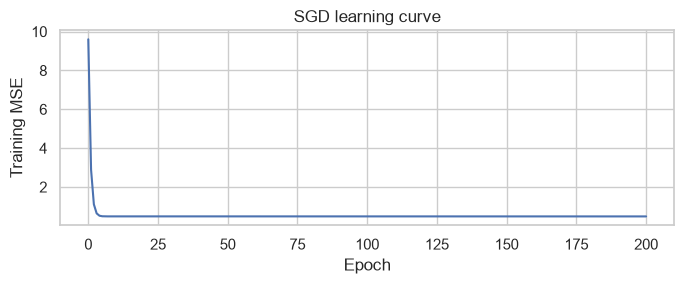

In [16]:
sgd_x = np.array([1.,2.,4.,3.,5.])
sgd_y = np.array([1.,3.,3.,2.,5.])
a,b,learning_rate = 0.,0.,0.01
history = [mean_squared_error(sgd_y,a+b*sgd_x)]
for epoch in range(200):
    for xi,yi in zip(sgd_x,sgd_y):
        error = a+b*xi-yi
        a,b = a-learning_rate*error,b-learning_rate*error*xi
    history.append(mean_squared_error(sgd_y,a+b*sgd_x))
ols = LinearRegression().fit(sgd_x.reshape(-1,1),sgd_y)
print(f'SGD: intercept={a:.5f}, slope={b:.5f}, MSE={history[-1]:.5f}')
print(f'OLS: intercept={ols.intercept_:.5f}, slope={ols.coef_[0]:.5f}')
print('유한 epoch·고정 학습률 SGD와 최소제곱법의 값은 정확히 같을 필요가 없다.')
plt.figure(figsize=(7,3))
plt.plot(history)
plt.xlabel('Epoch'); plt.ylabel('Training MSE'); plt.title('SGD learning curve')
plt.tight_layout(); plt.show()
assert np.isfinite(history).all() and history[-1] < history[0]

## 12. 과적합과 L1/L2 규제 회귀

수업 안내의 8차 다항 회귀를 별도 합성 데이터에 적용한다. y=sin(x)에 잡음을 추가해
30개의 학습 표본을 만들고, 잡음 없는 사인 곡선과의 차이를 관찰한다.
아래 합성 자료는 엑셀의 RAND 결과를 그대로 복제한 자료가 아니다.
Lasso는 L1 규제로 일부 계수를 0으로 만들 수 있고 Ridge는 L2 규제로 계수를 줄인다.
규제 모델은 다항 특성을 표준화한 다음 학습한다. 고정 alpha 예제이며 최적 alpha를 찾은 결과는 아니다.

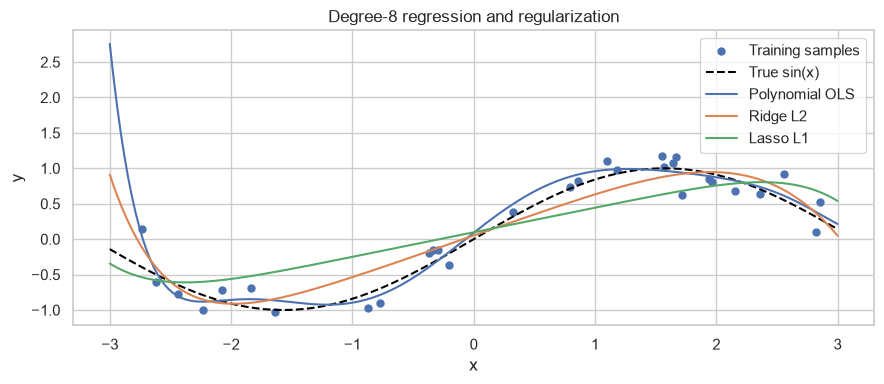

,model,train_MSE,truth_grid_MSE,nonzero_coefficients
0,Polynomial OLS,0.02636,0.14460,8
1,Ridge L2,0.06020,0.04702,8
2,Lasso L1,0.15357,0.12408,2


정규화가 항상 더 좋은 것은 아니다. 위 표의 실제 결과를 비교한다.


In [17]:
reg_rng = np.random.default_rng(SEED)
reg_x = np.sort(reg_rng.uniform(-3,3,30)).reshape(-1,1)
reg_y = np.sin(reg_x.ravel())+reg_rng.normal(0,.25,30)
reg_grid = np.linspace(-3,3,200).reshape(-1,1)
reg_truth = np.sin(reg_grid.ravel())
reg_models = {
    'Polynomial OLS': make_pipeline(PolynomialFeatures(8,include_bias=False),
        StandardScaler(),LinearRegression()),
    'Ridge L2': make_pipeline(PolynomialFeatures(8,include_bias=False),
        StandardScaler(),Ridge(alpha=1.0)),
    'Lasso L1': make_pipeline(PolynomialFeatures(8,include_bias=False),
        StandardScaler(),Lasso(alpha=.1,max_iter=100000,tol=1e-6)),
}
reg_results = []
fig,ax = plt.subplots(figsize=(9,4))
ax.scatter(reg_x.ravel(),reg_y,label='Training samples',s=25)
ax.plot(reg_grid.ravel(),reg_truth,'--',color='black',label='True sin(x)')
for name,model in reg_models.items():
    model.fit(reg_x,reg_y)
    pred = model.predict(reg_grid)
    reg_results.append({'model':name,'train_MSE':mean_squared_error(reg_y,model.predict(reg_x)),
        'truth_grid_MSE':mean_squared_error(reg_truth,pred),
        'nonzero_coefficients':int(np.count_nonzero(np.abs(model[-1].coef_)>1e-8))})
    ax.plot(reg_grid.ravel(),pred,label=name)
ax.set(xlabel='x',ylabel='y',title='Degree-8 regression and regularization')
ax.legend(); plt.tight_layout(); plt.show()
display(pd.DataFrame(reg_results).round(5))
print('정규화가 항상 더 좋은 것은 아니다. 위 표의 실제 결과를 비교한다.')

## 13. 결과 요약

실제 실행값으로 요약한다. 테스트 정확도가 높더라도 작은 Iris 표본에 대한 결과이므로
다른 데이터에서 동일한 성능이 나온다고 보장할 수 없다. 실행 시간은 PC와 라이브러리 버전에 따라 달라진다.

In [18]:
summary = {
    'selected_model': selected_name,
    'training_samples': len(X_train), 'test_samples': len(X_test),
    'best_selection_cv_accuracy': float(ranking.iloc[0]['cv_accuracy']),
    'baseline_test_accuracy': float(baseline_accuracy),
    'final_test_accuracy': float(final_accuracy),
    'final_test_macro_f1': float(f1_score(y_test,test_pred,average='macro')),
    'example_roc_auc': float(roc_auc_score(y_binary,scores_binary)),
    'example_average_precision': float(average_precision_score(y_binary,scores_binary)),
    'optuna_trials': len(study.trials),
}
display(pd.Series(summary, name='executed_result').to_frame())
print('모든 셀 실행 완료. 수식 직접 계산과 라이브러리 결과의 일치도 확인했다.')

,executed_result
selected_model,Optuna Random Forest
training_samples,120
test_samples,30
best_selection_cv_accuracy,0.966667
baseline_test_accuracy,0.333333
final_test_accuracy,0.966667
final_test_macro_f1,0.966583
example_roc_auc,0.697143
example_average_precision,0.516957
optuna_trials,50


모든 셀 실행 완료. 수식 직접 계산과 라이브러리 결과의 일치도 확인했다.


## 참고 자료

- [학교 과제: Machine Learning 실습파일 제출](https://eclass.kbu.ac.kr/mod/assign/view.php?id=500974)
- 과제 첨부 `Model Evaluation Selction.pdf` 4~16쪽: 혼동행렬, ROC/PR, 거리 계산.
- 과제 첨부 `model evaluation selection.xlsx`: 각 절에 사용한 시트와 셀 범위를 명시.
- [수업 공지 Prompts sharing](https://eclass.kbu.ac.kr/mod/ubboard/article.php?id=453777&bwid=69633)의
  `Machine Learning Study Guide.pdf`: Iris, 결정 트리, 앙상블, 규제, Optuna 실습.
- [scikit-learn 평가 지표 공식 문서](https://scikit-learn.org/stable/modules/model_evaluation.html)
- [scikit-learn 데이터 누출 방지 공식 문서](https://scikit-learn.org/stable/common_pitfalls.html)

참고 파일은 재배포하지 않고 필요한 수치 예제와 직접 실행한 구현을 정리했다.